In [1]:
import pandas as pd
import numpy as np
from PIL import Image

df_train = pd.read_csv("../data/train.csv")

path = df_train["path"][0]
img = np.array(Image.open(path))

print("Class:", df_train["label"][0])
print("Shape:", img.shape)
print("Min:", img.min(), "Max:", img.max())
print("First pixel (R, G, B):", img[0, 0])

Class: sea
Shape: (150, 150, 3)
Min: 0 Max: 255
First pixel (R, G, B): [104 116 130]


In [2]:
img_norm = img / 255.0

print("Before:", img.min(), img.max(), img.dtype)
print("After:", img_norm.min(), img_norm.max(), img_norm.dtype)
print("First pixel:", img_norm[0, 0])

Before: 0 255 uint8
After: 0.0 1.0 float64
First pixel: [0.40784314 0.45490196 0.50980392]


In [3]:
import tensorflow as tf

IMG_SIZE = 150

def load_image(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = img / 255.0
    return img

x = load_image(df_train["path"][0])
print("Shape:", x.shape)
print("Min:", float(tf.reduce_min(x)), "Max:", float(tf.reduce_max(x)))

I0000 00:00:1791904402.805912   40720 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791904402.806266   40720 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791904402.840569   40720 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791904403.578546   40720 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

Shape: (150, 150, 3)
Min: 0.0 Max: 1.0


E0000 00:00:1791904404.352808   40720 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [4]:
df_val = pd.read_csv("../data/val.csv")
df_test = pd.read_csv("../data/test.csv")

class_names = sorted(df_train["label"].unique())
class_to_idx = {name: i for i, name in enumerate(class_names)}

for df in (df_train, df_val, df_test):
    df["label_id"] = df["label"].map(class_to_idx)

print(class_to_idx)
df_train.head()

{'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


,path,label,label_id
0,../data/seg_train_test/seg_train/sea/12357.jpg,sea,4
1,../data/seg_train_test/seg_train/mountain/2428...,mountain,3
2,../data/seg_train_test/seg_train/glacier/3199.jpg,glacier,2
3,../data/seg_train_test/seg_train/glacier/22829...,glacier,2
4,../data/seg_train_test/seg_train/mountain/7865...,mountain,3


In [5]:
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_example(path, label):
    return load_image(path), label

def make_dataset(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (df["path"].values, df["label_id"].values)
    )
    if training:
        ds = ds.shuffle(len(df), seed=42)
    ds = ds.map(load_example, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(df_train, training=True)
val_ds = make_dataset(df_val)
test_ds = make_dataset(df_test)

for images, labels in train_ds.take(1):
    print("Images batch:", images.shape)
    print("Labels batch:", labels.shape)
    print("Labels:", labels.numpy())

Images batch: (32, 150, 150, 3)
Labels batch: (32,)
Labels: [4 2 4 4 3 4 5 2 2 0 1 0 4 1 5 3 1 0 0 4 2 2 0 2 5 1 1 1 3 3 0 4]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0134368].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0204003].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0096095].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0132334].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.003039].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0088483].


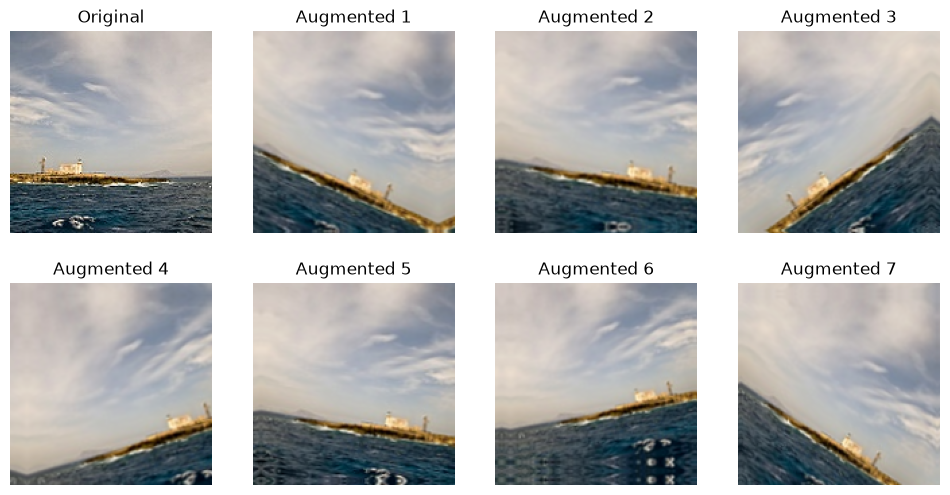

In [6]:
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.1),
])

original = load_image(df_train["path"][0])
original_batch = tf.expand_dims(original, 0)

plt.figure(figsize=(12, 6))

plt.subplot(2, 4, 1)
plt.imshow(original)
plt.title("Original")
plt.axis("off")

for i in range(2, 9):
    augmented = data_augmentation(original_batch, training=True)
    plt.subplot(2, 4, i)
    plt.imshow(augmented[0])
    plt.title(f"Augmented {i-1}")
    plt.axis("off")

plt.show()

Images batch: (32, 150, 150, 3)
Min: 0.0 Max: 1.0


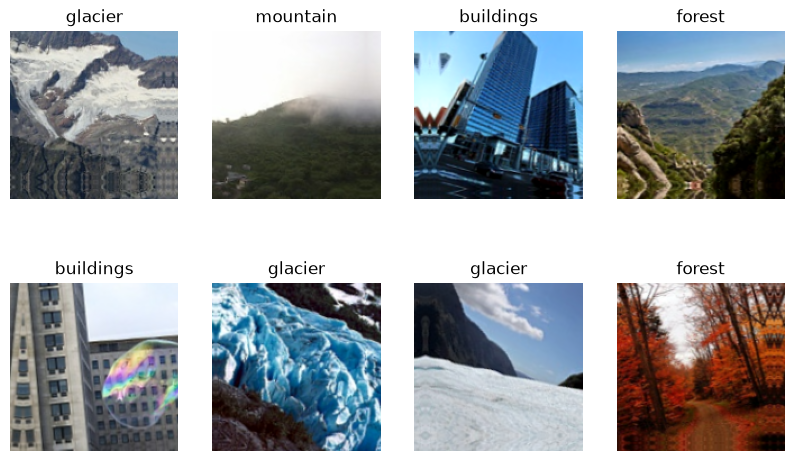

In [7]:
def augment(images, labels):
    images = data_augmentation(images, training=True)
    images = tf.clip_by_value(images, 0.0, 1.0)
    return images, labels

train_ds_aug = train_ds.map(augment, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# Check one batch
for images, labels in train_ds_aug.take(1):
    print("Images batch:", images.shape)
    print("Min:", float(tf.reduce_min(images)), "Max:", float(tf.reduce_max(images)))

plt.figure(figsize=(10, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i])
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.show()

In [8]:
conv = layers.Conv2D(filters=32, kernel_size=3, activation="relu")

batch_one = images[:1]
out = conv(batch_one)

print("Input shape:", batch_one.shape)
print("Output shape:", out.shape)

Input shape: (1, 150, 150, 3)
Output shape: (1, 148, 148, 32)


In [9]:
pool = layers.MaxPooling2D(pool_size=2)

out_pooled = pool(out)

print("Before pooling:", out.shape)
print("After pooling:", out_pooled.shape)

Before pooling: (1, 148, 148, 32)
After pooling: (1, 74, 74, 32)


In [10]:
blocks = keras.Sequential([
    keras.Input(shape=(150, 150, 3)),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(2),
])

blocks.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,248 (364.25 KB)

 Trainable params: 93,248 (364.25 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
head = keras.Sequential([
    keras.Input(shape=(17, 17, 128)),
    layers.GlobalAveragePooling2D(),
    layers.Dense(6, activation="softmax"),
])

head.summary()

fake = tf.random.normal((1, 17, 17, 128))
result = head(fake)
print("Output:", result.numpy().round(3))
print("Sum:", float(tf.reduce_sum(result)))

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 774 (3.02 KB)

 Trainable params: 774 (3.02 KB)

 Non-trainable params: 0 (0.00 B)

Output: [[0.179 0.153 0.166 0.162 0.169 0.17 ]]
Sum: 1.0


In [12]:
model = keras.Sequential([
    keras.Input(shape=(150, 150, 3)),

    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(128, 3, activation="relu"),
    layers.MaxPooling2D(2),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(6, activation="softmax"),
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 94,022 (367.27 KB)

 Trainable params: 94,022 (367.27 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("Compiled")

Compiled


In [16]:
for images, labels in val_ds.take(1):
    loss, acc = model.evaluate(images, labels, verbose=0)
    print("Loss:", round(loss, 3))
    print("Accuracy:", round(acc, 3))

Loss: 1.799
Accuracy: 0.188


In [17]:
from pathlib import Path

Path("../models").mkdir(exist_ok=True)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
    ),
    keras.callbacks.ModelCheckpoint(
        "../models/best_model.keras", monitor="val_loss", save_best_only=True
    ),
]

print("Callbacks ready:", [type(c).__name__ for c in callbacks])

Callbacks ready: ['EarlyStopping', 'ReduceLROnPlateau', 'ModelCheckpoint']


In [18]:
history = model.fit(
    train_ds_aug,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks,
)

Epoch 1/30


/home/amine/anaconda3/envs/ai/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


373/373 ━━━━━━━━━━━━━━━━━━━━ 131s 345ms/step - accuracy: 0.4546 - loss: 1.3168 - val_accuracy: 0.4628 - val_loss: 1.4459 - learning_rate: 0.0010
Epoch 2/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 151s 404ms/step - accuracy: 0.5366 - loss: 1.1466 - val_accuracy: 0.6070 - val_loss: 1.0592 - learning_rate: 0.0010
Epoch 3/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 46260s 124s/step - accuracy: 0.5796 - loss: 1.0712 - val_accuracy: 0.6383 - val_loss: 1.0064 - learning_rate: 0.0010
Epoch 4/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 138s 370ms/step - accuracy: 0.6001 - loss: 1.0310 - val_accuracy: 0.6513 - val_loss: 0.9415 - learning_rate: 0.0010
Epoch 5/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 137s 367ms/step - accuracy: 0.6298 - loss: 0.9698 - val_accuracy: 0.7042 - val_loss: 0.8235 - learning_rate: 0.0010
Epoch 6/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 135s 359ms/step - accuracy: 0.6486 - loss: 0.9319 - val_accuracy: 0.6575 - val_loss: 0.9490 - learning_rate: 0.0010
Epoch 7/30
373/373 ━━━━━━━━━━━━━━━━━━━━ 135s 360ms/step - accuracy: 0.6624

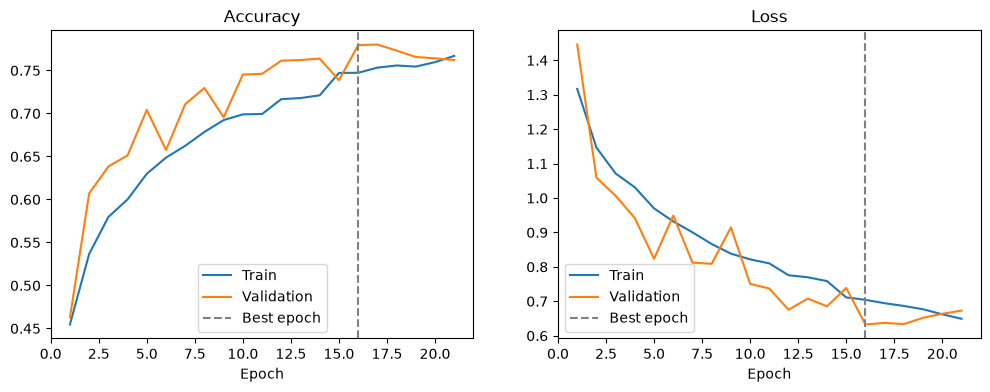

In [19]:
hist = history.history
epochs_range = range(1, len(hist["loss"]) + 1)
best_epoch = int(np.argmin(hist["val_loss"])) + 1

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, hist["accuracy"], label="Train")
axes[0].plot(epochs_range, hist["val_accuracy"], label="Validation")
axes[0].axvline(best_epoch, color="gray", linestyle="--", label="Best epoch")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(epochs_range, hist["loss"], label="Train")
axes[1].plot(epochs_range, hist["val_loss"], label="Validation")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label="Best epoch")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.show()

In [20]:
Path("../reports").mkdir(exist_ok=True)
fig.savefig("../reports/training_curves.png", dpi=150, bbox_inches="tight")

In [21]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print("Test loss:", round(test_loss, 3))
print("Test accuracy:", round(test_acc, 3))

Test loss: 0.633
Test accuracy: 0.786


In [22]:
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = df_test["label_id"].values

print("Probabilities shape:", y_prob.shape)
print("First 10 predicted:", y_pred[:10])
print("First 10 true:     ", y_true[:10])

Probabilities shape: (2553, 6)
First 10 predicted: [2 5 2 5 5 4 0 2 5 5]
First 10 true:      [2 1 2 5 5 3 0 2 5 5]


In [23]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

              precision    recall  f1-score   support

   buildings      0.784     0.637     0.703       394
      forest      0.926     0.968     0.946       411
     glacier      0.799     0.698     0.745       444
    mountain      0.752     0.725     0.738       455
         sea      0.763     0.803     0.783       417
      street      0.711     0.884     0.788       432

    accuracy                          0.786      2553
   macro avg      0.789     0.786     0.784      2553
weighted avg      0.788     0.786     0.783      2553



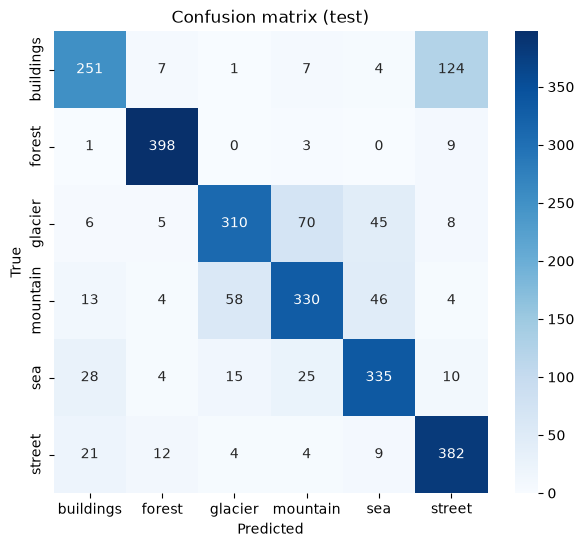

[[251   7   1   7   4 124]
 [  1 398   0   3   0   9]
 [  6   5 310  70  45   8]
 [ 13   4  58 330  46   4]
 [ 28   4  15  25 335  10]
 [ 21  12   4   4   9 382]]


In [24]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion matrix (test)")
plt.show()

fig.savefig("../reports/confusion_matrix.png", dpi=150, bbox_inches="tight")
print(cm)

Wrong predictions: 547


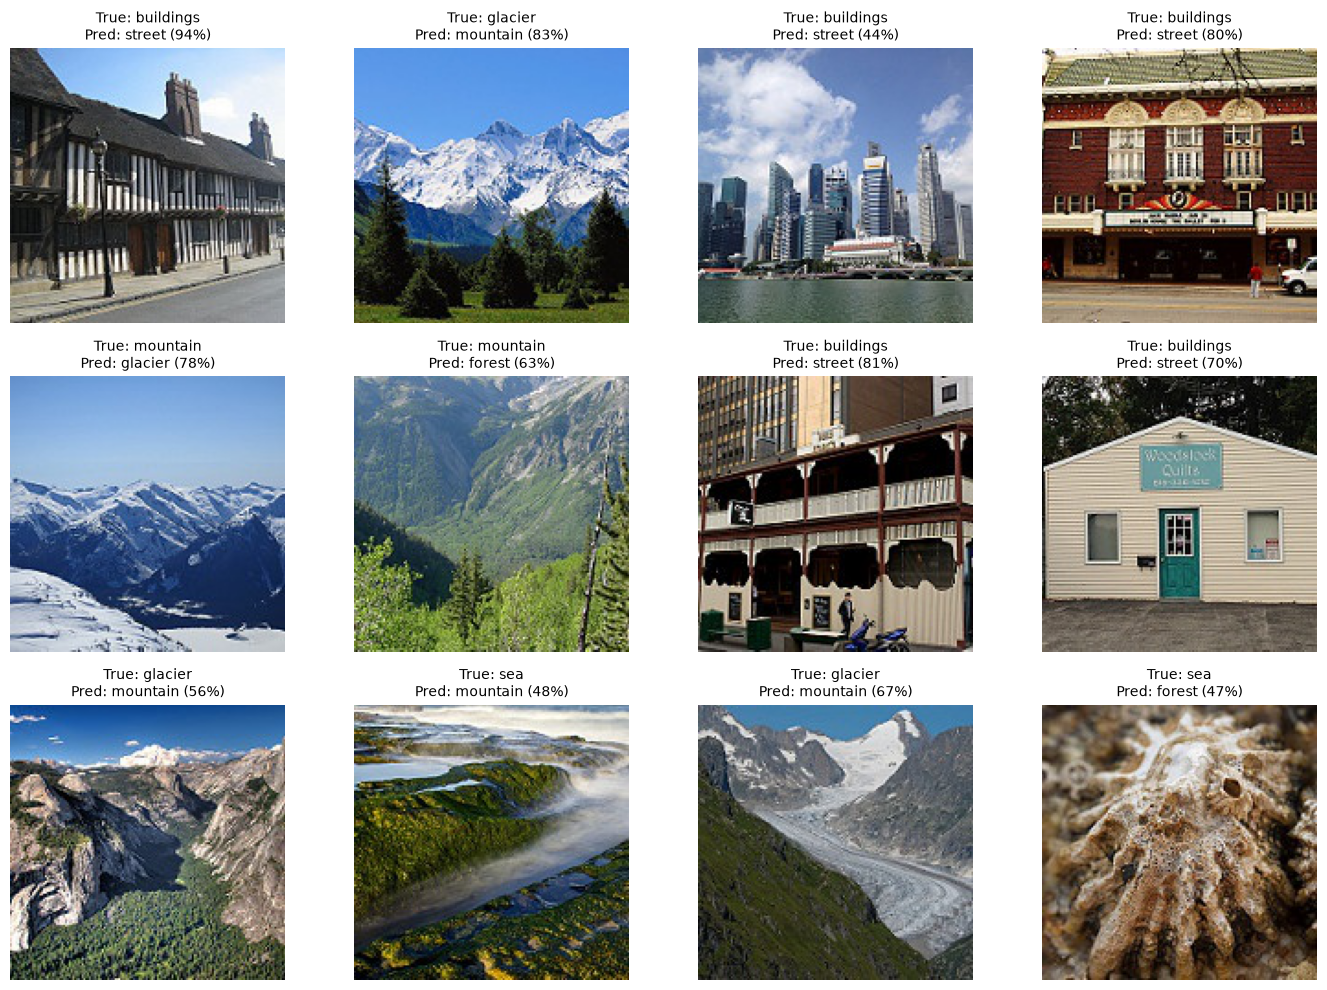

In [25]:
wrong = np.where(y_pred != y_true)[0]
print("Wrong predictions:", len(wrong))

rng = np.random.default_rng(1)
sample = rng.choice(wrong, size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, i in zip(axes.ravel(), sample):
    ax.imshow(Image.open(df_test["path"][i]))
    ax.set_title(
        f"True: {class_names[y_true[i]]}\n"
        f"Pred: {class_names[y_pred[i]]} ({y_prob[i, y_pred[i]]:.0%})",
        fontsize=10,
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

fig.savefig("../reports/wrong_predictions.png", dpi=150, bbox_inches="tight")

Correct predictions: 2006


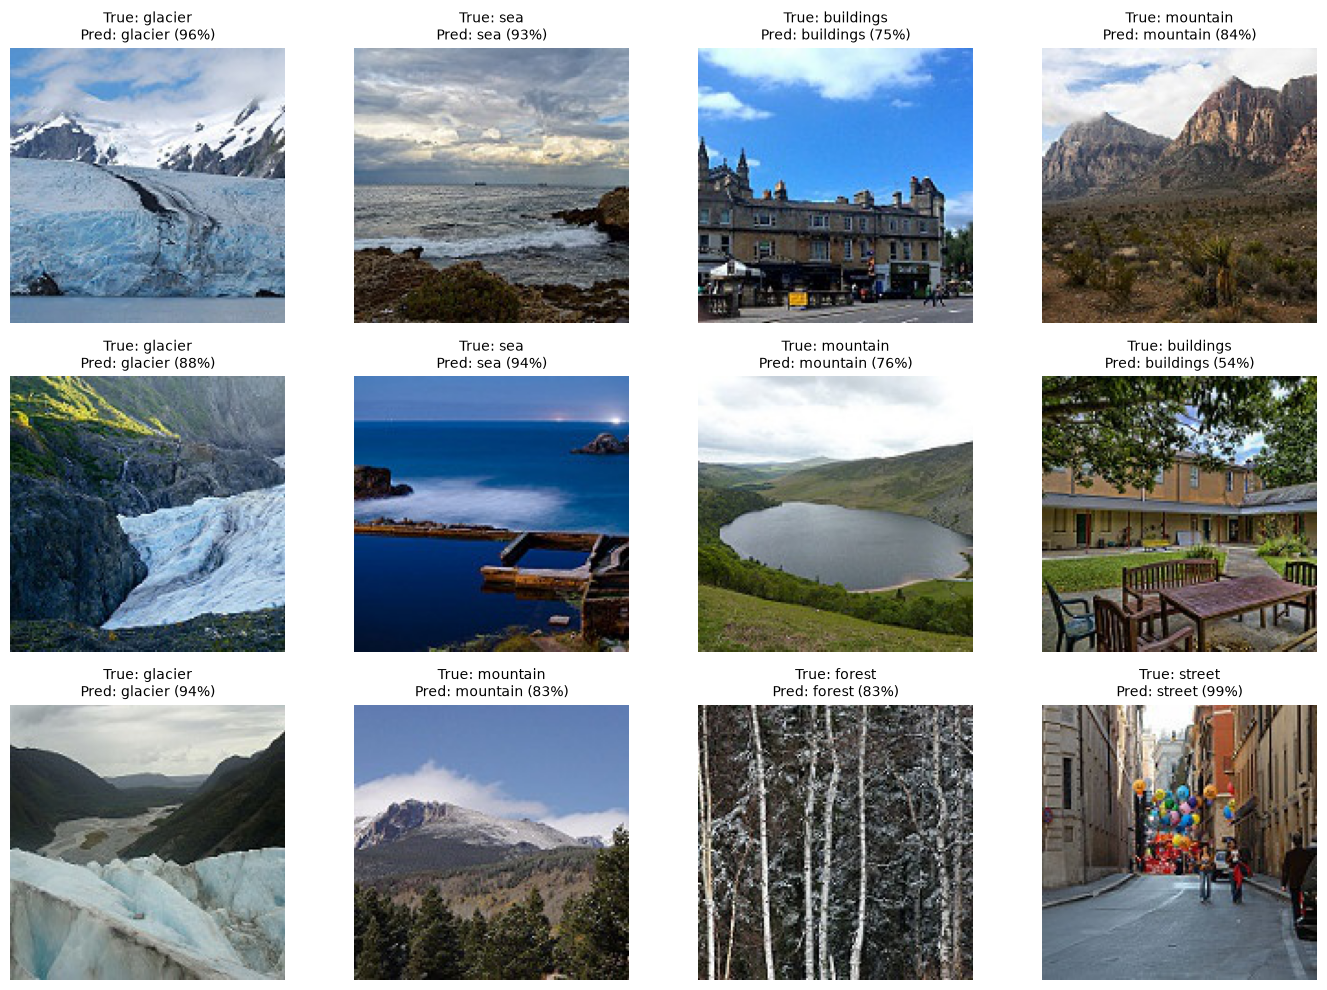

In [26]:
right = np.where(y_pred == y_true)[0]
print("Correct predictions:", len(right))

sample = rng.choice(right, size=12, replace=False)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, i in zip(axes.ravel(), sample):
    ax.imshow(Image.open(df_test["path"][i]))
    ax.set_title(
        f"True: {class_names[y_true[i]]}\n"
        f"Pred: {class_names[y_pred[i]]} ({y_prob[i, y_pred[i]]:.0%})",
        fontsize=10,
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

fig.savefig("../reports/correct_predictions.png", dpi=150, bbox_inches="tight")

In [27]:
def build_model(filters=(32, 64, 128), dropout=0.3, lr=0.001):
    m = keras.Sequential([keras.Input(shape=(150, 150, 3))])
    for f in filters:
        m.add(layers.Conv2D(f, 3, activation="relu"))
        m.add(layers.MaxPooling2D(2))
    m.add(layers.GlobalAveragePooling2D())
    m.add(layers.Dropout(dropout))
    m.add(layers.Dense(6, activation="softmax"))
    m.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return m


def make_callbacks(name):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
        keras.callbacks.ModelCheckpoint(f"../models/{name}.keras", monitor="val_loss", save_best_only=True),
    ]


results = {
    "A_baseline": {
        "params": model.count_params(),
        "epochs": len(hist["loss"]),
        "val_acc": round(hist["val_accuracy"][best_epoch - 1], 3),
        "test_acc": round(test_acc, 3),
    }
}
print(results)


{'A_baseline': {'params': 94022, 'epochs': 21, 'val_acc': 0.779, 'test_acc': 0.786}}


In [ ]:
model_b = build_model(filters=(32, 64, 128, 256), dropout=0.3, lr=0.001)
print("Params:", model_b.count_params())

history_b = model_b.fit(
    train_ds_aug,
    validation_data=val_ds,
    epochs=30,
    callbacks=make_callbacks("B_bigger"),
)

Params: 389958
Epoch 1/30


/home/amine/anaconda3/envs/ai/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 30/373 ━━━━━━━━━━━━━━━━━━━━ 2:07 373ms/step - accuracy: 0.3167 - loss: 1.5933